TensorFlow: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]

Dataset paths verified successfully.

real_notes
Total groups: 802
Training groups: 641
Validation groups: 161

fake_notes
Total groups: 588
Training groups: 470
Validation groups: 118

========== DATASET SUMMARY ==========
Training images: 13206
Validation images: 3811
real_notes Training: 3846 Validation: 966
fake_notes Training: 2820 Validation: 708
not_banknotes Training: 6540 Validation: 2137

Class weights: {0: 1.1445657826313052, 1: 1.5609929078014184, 2: 0.6730886850152905}

TensorFlow datasets created.
INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')

Number of GPUs: 2
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification_head (Dense)     │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

... (7 outputs left out)

 Non-trainable params: 2,566,211 (9.79 MB)

Epoch 1/5
INFO:tensorflow:Collective all_reduce tensors: 16 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1


E0000 00:00:1795560513.146576      23 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


825/826 ━━━━━━━━━━━━━━━━━━━━ 0s 253ms/step - accuracy: 0.9790 - loss: 0.0973
Epoch 1: val_loss improved from 0.07551 to 0.05400, saving model to /kaggle/working/best_efficientnetb0_3class.keras

Epoch 1: finished saving model to /kaggle/working/best_efficientnetb0_3class.keras
826/826 ━━━━━━━━━━━━━━━━━━━━ 280s 326ms/step - accuracy: 0.9811 - loss: 0.0867 - val_accuracy: 0.9856 - val_loss: 0.0540 - learning_rate: 1.0000e-05
Epoch 2/5
825/826 ━━━━━━━━━━━━━━━━━━━━ 0s 255ms/step - accuracy: 0.9851 - loss: 0.0736
Epoch 2: val_loss improved from 0.05400 to 0.04799, saving model to /kaggle/working/best_efficientnetb0_3class.keras

Epoch 2: finished saving model to /kaggle/working/best_efficientnetb0_3class.keras
826/826 ━━━━━━━━━━━━━━━━━━━━ 268s 324ms/step - accuracy: 0.9842 - loss: 0.0728 - val_accuracy: 0.9887 - val_loss: 0.0480 - learning_rate: 1.0000e-05
Epoch 3/5
825/826 ━━━━━━━━━━━━━━━━━━━━ 0s 257ms/step - accuracy: 0.9860 - loss: 0.0600
Epoch 3: val_loss improved from 0.04799 to 0.0438

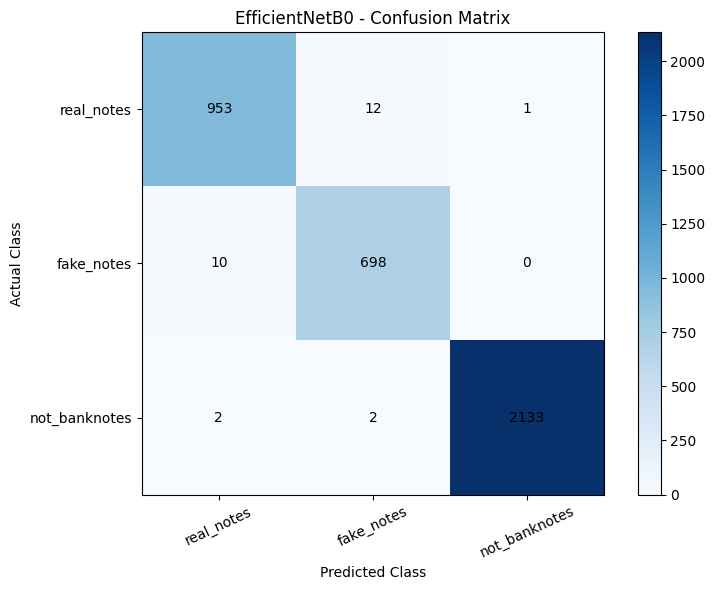


========== PER-CLASS PERFORMANCE ==========
           Class  Precision  Recall  F1_Score  Support
0     real_notes     0.9876  0.9865    0.9871      966
1     fake_notes     0.9803  0.9859    0.9831      708
2  not_banknotes     0.9995  0.9981    0.9988     2137


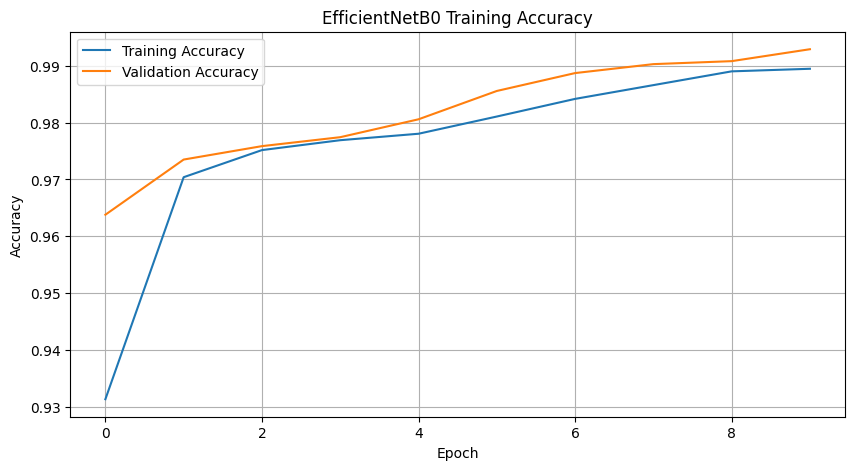

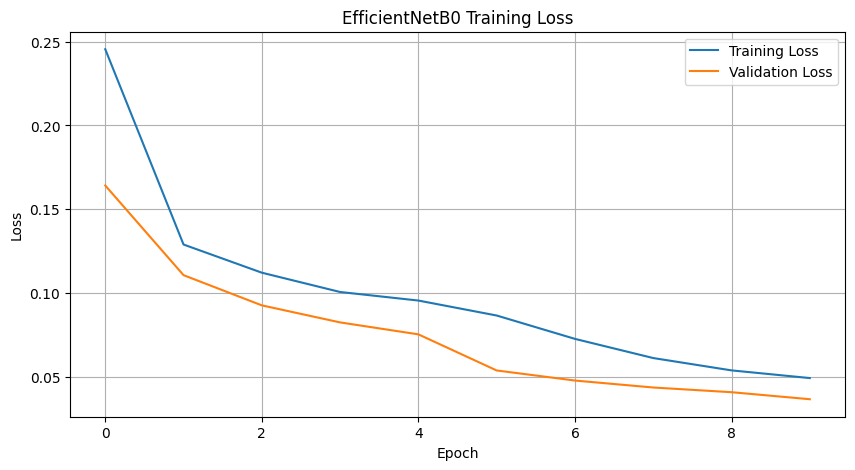


EFFICIENTNETB0 TRAINING COMPLETED
Validation Accuracy: 99.29%

Final Model:
/kaggle/working/efficientnetb0_3class_final.keras

Best Model:
/kaggle/working/best_efficientnetb0_3class.keras

Backup ZIP:
/kaggle/working/banknote_final_backup.zip

Saved Files:
 - best_efficientnetb0_3class.keras
 - efficientnetb0_3class_final.keras
 - classification_report.csv
 - confusion_matrix.csv
 - confusion_matrix.png
 - per_class_metrics.csv
 - validation_predictions.csv
 - class_mapping_3class.json
 - model_summary.json
 - training_history.csv
 - training_accuracy.png
 - training_loss.png

ALL TASKS COMPLETED SUCCESSFULLY!


In [1]:

# ============================================================
# BANGLADESHI BANKNOTE CLASSIFIER
# EfficientNetB0 - COMPLETE FINAL TRAINING PIPELINE
# Classes: Real Notes, Fake Notes, Non-Banknotes
# ============================================================

import os
import re
import json
import random
import shutil
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from collections import defaultdict
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support
)

from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0

# ============================================================
# 1. CONFIGURATION
# ============================================================

SEED = 42

IMG_SIZE = 224
BATCH_SIZE = 16

HEAD_EPOCHS = 5
FINE_TUNE_EPOCHS = 5

OUTPUT_DIR = "/kaggle/working"

JAAL_PATH = (
    "/kaggle/input/datasets/siamahmedkaggle/"
    "jaaltaka-dataset-for-bangladeshi-banknotes"
)

CALTECH_PATH = (
    "/kaggle/input/datasets/imbikramsaha/"
    "caltech-101/caltech-101"
)

CLASS_NAMES = [
    "real_notes",
    "fake_notes",
    "not_banknotes"
]

NUM_CLASSES = len(CLASS_NAMES)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

# ============================================================
# 2. VERIFY DATASET PATHS
# ============================================================

assert os.path.isdir(JAAL_PATH), "JaalTaka dataset not found!"
assert os.path.isdir(CALTECH_PATH), "Caltech dataset not found!"

for category in ["real_notes", "fake_notes"]:
    assert os.path.isdir(
        os.path.join(JAAL_PATH, category)
    ), f"{category} folder not found!"

print("\nDataset paths verified successfully.")

# ============================================================
# 3. COLLECT REAL AND FAKE BANKNOTE GROUPS
# ============================================================

train_paths = []
train_labels = []

val_paths = []
val_labels = []

banknote_split_summary = {}

for label, category in enumerate(["real_notes", "fake_notes"]):

    folder = os.path.join(JAAL_PATH, category)

    groups = defaultdict(list)

    for root, dirs, files in os.walk(folder):

        for filename in files:

            if filename.lower().endswith(
                (".jpg", ".jpeg", ".png")
            ):

                match = re.match(
                    r"(note_\d+)_\d+",
                    filename,
                    re.IGNORECASE
                )

                if match:

                    note_id = match.group(1)

                    groups[note_id].append(
                        os.path.join(root, filename)
                    )

    note_ids = sorted(groups.keys())

    if len(note_ids) == 0:
        raise ValueError(
            f"No banknote groups found in {category}"
        )

    train_ids, val_ids = train_test_split(
        note_ids,
        test_size=0.20,
        random_state=SEED
    )

    for note_id in train_ids:

        for image_path in groups[note_id]:

            train_paths.append(image_path)
            train_labels.append(label)

    for note_id in val_ids:

        for image_path in groups[note_id]:

            val_paths.append(image_path)
            val_labels.append(label)

    banknote_split_summary[category] = {
        "total_groups": len(note_ids),
        "train_groups": len(train_ids),
        "validation_groups": len(val_ids)
    }

    print(f"\n{category}")
    print("Total groups:", len(note_ids))
    print("Training groups:", len(train_ids))
    print("Validation groups:", len(val_ids))

# ============================================================
# 4. COLLECT CALTECH NON-BANKNOTE IMAGES
# ============================================================

categories = [
    category
    for category in os.listdir(CALTECH_PATH)
    if category != "BACKGROUND_Google"
    and os.path.isdir(
        os.path.join(CALTECH_PATH, category)
    )
]

categories.sort()

if len(categories) != 101:
    raise ValueError(
        f"Expected 101 Caltech categories, found {len(categories)}"
    )

random.Random(SEED).shuffle(categories)

train_categories = categories[:81]
val_categories = categories[81:]

for category in train_categories:

    folder = os.path.join(CALTECH_PATH, category)

    for filename in os.listdir(folder):

        if filename.lower().endswith(
            (".jpg", ".jpeg", ".png")
        ):

            train_paths.append(
                os.path.join(folder, filename)
            )

            train_labels.append(2)

for category in val_categories:

    folder = os.path.join(CALTECH_PATH, category)

    for filename in os.listdir(folder):

        if filename.lower().endswith(
            (".jpg", ".jpeg", ".png")
        ):

            val_paths.append(
                os.path.join(folder, filename)
            )

            val_labels.append(2)

# ============================================================
# 5. SHUFFLE TRAINING DATA
# ============================================================

combined = list(zip(train_paths, train_labels))

random.Random(SEED).shuffle(combined)

train_paths, train_labels = zip(*combined)

train_paths = list(train_paths)

train_labels = np.array(
    train_labels,
    dtype=np.int32
)

val_labels = np.array(
    val_labels,
    dtype=np.int32
)

print("\n========== DATASET SUMMARY ==========")

print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))

for i, name in enumerate(CLASS_NAMES):

    print(
        name,
        "Training:",
        int(np.sum(train_labels == i)),
        "Validation:",
        int(np.sum(val_labels == i))
    )

assert len(train_paths) == len(train_labels)
assert len(val_paths) == len(val_labels)

# ============================================================
# 6. CLASS WEIGHTS
# ============================================================

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(NUM_CLASSES),
    y=train_labels
)

class_weights = {
    i: float(weights[i])
    for i in range(NUM_CLASSES)
}

print("\nClass weights:", class_weights)

# ============================================================
# 7. IMAGE LOADING
# ============================================================

def load_image(path, label):

    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    image = tf.cast(image, tf.float32)

    return image, label


def create_dataset(paths, labels, training=False):

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:

        dataset = dataset.shuffle(
            buffer_size=4000,
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(
        tf.data.AUTOTUNE
    )

    return dataset


train_ds = create_dataset(
    train_paths,
    train_labels,
    training=True
)

val_ds = create_dataset(
    val_paths,
    val_labels,
    training=False
)

print("\nTensorFlow datasets created.")

# ============================================================
# 8. TWO GPU STRATEGY
# ============================================================

strategy = tf.distribute.MirroredStrategy()

print(
    "\nNumber of GPUs:",
    strategy.num_replicas_in_sync
)

# ============================================================
# 9. BUILD EFFICIENTNETB0
# ============================================================

with strategy.scope():

    base_model = EfficientNetB0(
        weights="imagenet",
        include_top=False,
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )

    base_model.trainable = False

    inputs = layers.Input(
        shape=(IMG_SIZE, IMG_SIZE, 3)
    )

    # EfficientNetB0 includes its own preprocessing.
    # Input values remain in the 0-255 range.

    x = base_model(
        inputs,
        training=False
    )

    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dropout(0.3)(x)

    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax",
        name="classification_head"
    )(x)

    model = models.Model(
        inputs=inputs,
        outputs=outputs
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

model.summary()

# ============================================================
# 10. CALLBACKS
# ============================================================

BEST_MODEL_PATH = os.path.join(
    OUTPUT_DIR,
    "best_efficientnetb0_3class.keras"
)

callbacks = [

    tf.keras.callbacks.ModelCheckpoint(
        BEST_MODEL_PATH,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.00001,
        verbose=1
    )
]

# ============================================================
# 11. PHASE 1: TRAIN CLASSIFICATION HEAD
# ============================================================

print("\n========== PHASE 1: HEAD TRAINING ==========")

history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=HEAD_EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks
)

# ============================================================
# 12. PHASE 2: FINE-TUNING
# ============================================================

print("\n========== PHASE 2: FINE-TUNING ==========")

with strategy.scope():

    base_model.trainable = True

    # Keep most pretrained layers frozen.
    # Fine-tune only the last 30 layers.

    for layer in base_model.layers[:-30]:
        layer.trainable = False

    # Batch normalization layers remain frozen.
    for layer in base_model.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.00001
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

model.summary()

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINE_TUNE_EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks
)

# ============================================================
# 13. LOAD BEST CHECKPOINT
# ============================================================

print("\nLoading best checkpoint...")

best_model = tf.keras.models.load_model(
    BEST_MODEL_PATH
)

FINAL_MODEL_PATH = os.path.join(
    OUTPUT_DIR,
    "efficientnetb0_3class_final.keras"
)

best_model.save(FINAL_MODEL_PATH)

print("Best model saved successfully.")

# ============================================================
# 14. VALIDATION PREDICTIONS
# ============================================================

print("\nGenerating validation predictions...")

probabilities = best_model.predict(
    val_ds,
    verbose=1
)

y_pred = np.argmax(
    probabilities,
    axis=1
)

y_true = val_labels

# ============================================================
# 15. ACCURACY
# ============================================================

accuracy = accuracy_score(
    y_true,
    y_pred
)

print("\n========== VALIDATION ACCURACY ==========")

print(
    f"Accuracy: {accuracy * 100:.2f}%"
)

# ============================================================
# 16. CLASSIFICATION REPORT
# ============================================================

report = classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

print("\n========== CLASSIFICATION REPORT ==========")

print(report_df.round(4))

report_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "classification_report.csv"
    )
)

# ============================================================
# 17. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2]
)

cm_df = pd.DataFrame(
    cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
)

print("\n========== CONFUSION MATRIX ==========")

print(cm_df)

cm_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "confusion_matrix.csv"
    )
)

# Save confusion matrix image
plt.figure(figsize=(8, 6))

plt.imshow(cm, cmap="Blues")

plt.title("EfficientNetB0 - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(
    range(NUM_CLASSES),
    CLASS_NAMES,
    rotation=25
)

plt.yticks(
    range(NUM_CLASSES),
    CLASS_NAMES
)

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "confusion_matrix.png"
    ),
    dpi=300
)

plt.show()
plt.close()

# ============================================================
# 18. PER-CLASS METRICS
# ============================================================

precision, recall, f1, support = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        zero_division=0
    )
)

metrics_df = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Precision": precision,
    "Recall": recall,
    "F1_Score": f1,
    "Support": support
})

print("\n========== PER-CLASS PERFORMANCE ==========")

print(metrics_df.round(4))

metrics_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "per_class_metrics.csv"
    ),
    index=False
)

# ============================================================
# 19. SAVE VALIDATION PREDICTIONS
# ============================================================

predictions_df = pd.DataFrame({

    "image_path": val_paths,

    "actual_class": [
        CLASS_NAMES[i] for i in y_true
    ],

    "predicted_class": [
        CLASS_NAMES[i] for i in y_pred
    ],

    "confidence": np.max(
        probabilities,
        axis=1
    )
})

predictions_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "validation_predictions.csv"
    ),
    index=False
)

# ============================================================
# 20. SAVE CLASS MAPPING
# ============================================================

class_mapping = {
    "real_notes": 0,
    "fake_notes": 1,
    "not_banknotes": 2
}

with open(
    os.path.join(
        OUTPUT_DIR,
        "class_mapping_3class.json"
    ),
    "w"
) as f:

    json.dump(
        class_mapping,
        f,
        indent=4
    )

# ============================================================
# 21. SAVE MODEL SUMMARY
# ============================================================

summary = {

    "model": "EfficientNetB0",

    "pretrained_weights": "ImageNet",

    "input_size": [224, 224, 3],

    "num_classes": NUM_CLASSES,

    "class_names": CLASS_NAMES,

    "validation_accuracy": float(accuracy),

    "training_images": int(len(train_paths)),

    "validation_images": int(len(val_paths)),

    "banknote_group_split": banknote_split_summary,

    "caltech_train_categories": train_categories,

    "caltech_validation_categories": val_categories,

    "training_strategy": "Transfer Learning + Fine Tuning"
}

with open(
    os.path.join(
        OUTPUT_DIR,
        "model_summary.json"
    ),
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=4
    )

# ============================================================
# 22. SAVE TRAINING HISTORY
# ============================================================

history_data = {}

for key in history_head.history:

    history_data[key] = (
        history_head.history[key]
        + history_fine.history.get(key, [])
    )

history_df = pd.DataFrame(history_data)

history_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "training_history.csv"
    ),
    index=False
)

# ============================================================
# 23. PLOT TRAINING HISTORY
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    history_data["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_data["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("EfficientNetB0 Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "training_accuracy.png"
    ),
    dpi=300
)

plt.show()
plt.close()

plt.figure(figsize=(10, 5))

plt.plot(
    history_data["loss"],
    label="Training Loss"
)

plt.plot(
    history_data["val_loss"],
    label="Validation Loss"
)

plt.title("EfficientNetB0 Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "training_loss.png"
    ),
    dpi=300
)

plt.show()
plt.close()

# ============================================================
# 24. CREATE FINAL BACKUP
# ============================================================

backup_folder = os.path.join(
    OUTPUT_DIR,
    "banknote_final_backup"
)

os.makedirs(
    backup_folder,
    exist_ok=True
)

files_to_backup = [

    "best_efficientnetb0_3class.keras",

    "efficientnetb0_3class_final.keras",

    "classification_report.csv",

    "confusion_matrix.csv",

    "confusion_matrix.png",

    "per_class_metrics.csv",

    "validation_predictions.csv",

    "class_mapping_3class.json",

    "model_summary.json",

    "training_history.csv",

    "training_accuracy.png",

    "training_loss.png"
]

for filename in files_to_backup:

    source = os.path.join(
        OUTPUT_DIR,
        filename
    )

    if os.path.isfile(source):

        shutil.copy2(
            source,
            backup_folder
        )

zip_path = shutil.make_archive(
    os.path.join(
        OUTPUT_DIR,
        "banknote_final_backup"
    ),
    "zip",
    backup_folder
)

# ============================================================
# 25. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 55)

print("EFFICIENTNETB0 TRAINING COMPLETED")

print("=" * 55)

print(
    "Validation Accuracy:",
    f"{accuracy * 100:.2f}%"
)

print("\nFinal Model:")
print(FINAL_MODEL_PATH)

print("\nBest Model:")
print(BEST_MODEL_PATH)

print("\nBackup ZIP:")
print(zip_path)

print("\nSaved Files:")

for filename in files_to_backup:
    print(" -", filename)

print("\nALL TASKS COMPLETED SUCCESSFULLY!")
